# Análisis y entrenamiento de modelo sobre dataset de GOG

**Alumno**: Julián Agustín Carola

**Objetivo.** El objetivo va a ser el evaluar cuanto se puede estimar la valoración de un videojuego a partir de qué categoría es el videojuego, cuál es su desarrolladora, cuál es su publicadora, cuál fue el año donde se lanzó y a qué precio usando modelos de Machine Learning

El dataset que se usó se extrajo de Kaggle (https://www.kaggle.com/datasets/lunthu/gog-com-video-games-dataset) que recopila más de 10.000 **items** de la tienda de venta de videojuegos GOG. Victor Laputsky, el creador del dataset, extrajo estos datos a través de la API de GOG.com en junio del 2025.

Si bien el dataset incluye todo tipo de ítems de la tienda de GOG (dlcs, soundtracks, etc...) se van a excluir de este análisis porque no es lo que nos interesa a nosotros para el estudio.

En la descripción del dataset en Kaggle se puede encontrar información detallada sobre cada una de las columnas y su significado. A continuación, se presenta un resumen de las columnas que nos serán útiles para el trabajo.

### 1. Columnas de identificación

- <u>id</u>: Identificador numérico del videojuego dentro de la tienda GOG. Se utilizará para identificar registros y detectar posibles duplicados. No se utilizará como variable predictora.

- <u>title</u>: Título del videojuego. Se utilizará para identificar los productos.

### 2. Columnas utilizadas para la limpieza y el filtrado

- <u>type</u>: Tipo de producto registrado en GOG. Puede tomar tres valores:
  - `1`: Videojuegos.
  - `2`: Paquetes de productos (bundles).
  - `3`: Contenido descargable (DLC).

  Se utilizará para conservar únicamente los videojuegos (`type == 1`), excluyendo paquetes y contenido descargable.

- <u>reviewCount</u>: Cantidad de reseñas registradas para el videojuego. Se utilizará para seleccionar aquellos videojuegos que tengan una cantidad mínima de reseñas, con el objetivo de trabajar con valoraciones respaldadas por varias opiniones. Vamos a tomar como criterio arbitrario un límite de 5 reviews al menos.

- <u>isInDevelopment</u>: Variable booleana que indica si el videojuego se encuentra en desarrollo. Se van a excluir, ya que son los juegos que están en early access.

### 3. Columnas predictoras

Son las características que se utilizarán para intentar predecir la valoración de un videojuego.

- <u>developer</u>: Nombre de la empresa o equipo desarrollador del videojuego. Permitirá analizar si existen asociaciones entre las desarrolladoras y las valoraciones recibidas por sus productos.

- <u>publisher</u>: Nombre de la empresa encargada de publicar o distribuir el videojuego. Permitirá analizar si determinadas publicadoras presentan diferencias en las valoraciones de sus títulos.

- <u>category</u>: Género principal del videojuego. Por ejemplo: Action, Adventure, Strategy o Role-playing. Permitirá estudiar las diferencias en las valoraciones entre géneros.

- <u>genres</u>: Lista de géneros a los que pertenece el videojuego. A diferencia de `category`, permite representar múltiples géneros para un mismo título. Se evaluará su incorporación mediante una transformación de variables categóricas multietiqueta.

- <u>supportedOperatingSystems</u>: Lista de sistemas operativos compatibles con el videojuego, como Windows, Linux y macOS. Se evaluará si la compatibilidad con distintos sistemas operativos aporta información útil para predecir las valoraciones.

- <u>dateReleaseDate</u>: Fecha de lanzamiento del videojuego, expresada como fecha y hora. Según la documentación del dataset, contiene valores algo más precisos que `dateGlobal`. Se utilizará para obtener el año de lanzamiento.

- <u>ageLimit</u>: Restricción de edad asociada al videojuego, representada mediante un número entero. Permitirá analizar posibles diferencias de valoración entre productos destinados a distintos públicos.

- <u>baseAmount</u>: Precio base del videojuego, sin aplicar descuentos. Se utilizará para investigar si existe alguna asociación entre el precio y la valoración del producto.

- <u>isFree</u>: Variable booleana que indica si el videojuego es gratuito (free-to-play). Permitirá distinguir entre videojuegos gratuitos y pagos.

### 4. Variable objetivo

- <u>overallAvgRating</u>: Valoración promedio del videojuego considerando las opiniones de todas las ubicaciones e idiomas registrados por GOG. Es una variable numérica de tipo flotante y será la variable objetivo que intentarán predecir los modelos.

### 5. Columnas complementarias

Estas columnas pueden resultar útiles para estudiar la calidad de los datos, pero no se utilizarán directamente como variables predictoras.

- <u>rating</u>: Valor de puntuación interno del sistema de GOG, representado mediante un número entero. Según la documentación del dataset, su interpretación es difícil de determinar.

- <u>filteredAvgRating</u>: Valoración promedio correspondiente a las reseñas de usuarios de la ubicación o idioma inglés. No se utilizará para predecir `overallAvgRating`, debido a que ambas columnas contienen información directamente relacionada.

- <u>dateGlobal</u>: Fecha global de lanzamiento del videojuego, expresada como fecha y hora. Podrá utilizarse como alternativa cuando `dateReleaseDate` no contenga información válida.

- <u>originalCategory</u>: Género original asignado al videojuego. Es similar a `category`, pero puede contener información menos actualizada. Se conservará como referencia para comprobar diferencias entre ambas clasificaciones.

## 1. Importación y lectura del CSV

Se muestran las dimensiones y los tipos de columnas para que cualquier cambio del dataset sea visible.

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

RANDOM_STATE = 42
RUTA_CSV = Path('./gog_games_dataset.csv')
if not RUTA_CSV.exists():
    raise FileNotFoundError(f'No encuentro {RUTA_CSV.resolve()}. Colocá el CSV junto al notebook.')

df = pd.read_csv(RUTA_CSV, on_bad_lines='skip')
print('Dimensiones originales:', df.shape)
display(df.head(3))

Dimensiones originales: (10896, 51)


,id,developer,publisher,gallery,video,supportedOperatingSystems,genres,globalReleaseDate,isTBA,isDiscounted_main,...,isFree,discount,promoId,filteredAvgRating,overallAvgRating,reviewCount,isReviewable,reviewPages,dateGlobal,dateReleaseDate
0,4,Volition,Interplay,['//images-4.gog-statics.com/4e4c85f81ebb0f1a1...,NaN,['windows'],"['Simulation', 'Combat', 'Sci-fi']",889653600.0,False,False,...,False,0,NaN,4.4,4.7,117,True,11,3/11/1998 22:00,3/11/1998 22:00
1,5,Volition,Interplay,['//images-2.gog-statics.com/1f3d26426fba87f09...,NaN,['windows'],"['Simulation', 'Combat', 'Sci-fi']",938638800.0,False,False,...,False,0,NaN,4.6,4.8,328,True,31,9/29/1999 21:00,9/29/1999 21:00
2,6,Shiny Entertainment,Interplay,['//images-1.gog-statics.com/1c95f819fe0d6e759...,NaN,['windows'],"['Action', 'TPP', 'Sci-fi']",862347600.0,False,True,...,False,20,2025_summer_sale_1,4.2,4.4,148,True,14,4/29/1997 21:00,4/29/1997 21:00


## 2. Auditoría inicial de calidad de datos

Antes de filtrar se revisan **todas las columnas** y luego se profundiza en las necesarias para el análisis. `isna()` identifica nulos explícitos, pero no necesariamente cadenas vacías, listas vacías ni valores especiales como cero.

In [8]:
auditoria_general = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'valores_distintos': df.nunique(dropna=True)
}).sort_values(['nulos'], ascending=False)

display(auditoria_general)

columnas_relevantes = [
    'id','title','type','isInDevelopment','reviewCount','overallAvgRating',
    'filteredAvgRating','rating','developer','publisher','category','genres',
    'supportedOperatingSystems','dateReleaseDate','dateGlobal',
    'ageLimit','baseAmount','isFree'
]

display(auditoria_general.loc[columnas_relevantes])

,tipo,nulos,valores_distintos
video,str,3935,5606
promoId,str,2988,32
globalReleaseDate,float64,503,3554
dateReleaseDate,str,503,3554
dateGlobal,str,503,3554
releaseDate,float64,503,3554
publisher,str,0,1582
genres,str,0,950
developer,str,0,3437
id,int64,0,10896


,tipo,nulos,valores_distintos
id,int64,0,10896
title,str,0,10892
type,int64,0,3
isInDevelopment,bool,0,2
reviewCount,int64,0,380
overallAvgRating,float64,0,42
filteredAvgRating,float64,0,42
rating,int64,0,41
developer,str,0,3437
publisher,str,0,1582


## 3. Comprobaciones previas a los filtros


### 3.1. Tipo de producto

En la descripción del dataset nos aclaraba que la feature de tipo en el dataset nos indicaba si era un juego (tipo 1), bundle (tipo 2) o dlc (tipo 3).

Vamos a explorar los tipos para ver si lo que dice es verdad, cuantos hay y qué ejemplos se puden ver de cada tipo.

Para esto vamos a crear un diccionario con los distintos significados de los tipos y después vamos a recorrer el dataframe según los distintos types.

In [9]:
nombres_tipo = {1:'Videojuego', 2:'Bundle', 3:'DLC'}

resumen_tipos = df['type'].value_counts(dropna=False).sort_index().reset_index(name='registros')

resumen_tipos['descripcion'] = resumen_tipos['type'].map(nombres_tipo)

display(resumen_tipos[['type','descripcion','registros']])

columnas_ejemplos = ['id','title','type','category','reviewCount','overallAvgRating']

for tipo in (1,2,3):
    print(f'Ejemplos de {nombres_tipo[tipo]} (type = {tipo}):')
    display(df.loc[df['type'].eq(tipo), columnas_ejemplos].head(5))

,type,descripcion,registros
0,1,Videojuego,5653
1,2,Bundle,1402
2,3,DLC,3841


Ejemplos de Videojuego (type = 1):


,id,title,type,category,reviewCount,overallAvgRating
0,4,Descent: Freespace Battle Pack,1,Simulation,117,4.7
1,5,Freespace 2,1,Simulation,328,4.8
2,6,MDK,1,Action,148,4.4
3,7,Messiah,1,Action,57,3.7
4,8,Lionheart: Legacy of the Crusader,1,Role-playing,75,3.6


Ejemplos de Bundle (type = 2):


,id,title,type,category,reviewCount,overallAvgRating
6,10,M.A.X. + M.A.X. 2,2,Strategy,65,4.3
26,1075216797,Greak: Memories of Azur - Deluxe Edition,2,Action,5,4.3
30,1075465038,Geneforge Saga Bundle,2,Adventure,0,3.0
41,1076602098,Beautiful Indie Worlds Bundle,2,Action,0,1.0
45,1076704248,Kingdom Come: Deliverance II,2,Adventure,40,3.9


Ejemplos de DLC (type = 3):


,id,title,type,category,reviewCount,overallAvgRating
7,1073747344,The Fermi Paradox - Soundtrack,3,Simulation,0,0.0
8,1073861653,EVERSPACE™ 2 - Supporter Pack,3,Role-playing,1,5.0
11,1073986506,The Medium Deluxe Edition Upgrade,3,Adventure,0,2.0
12,1074122773,Tales of Maj'Eyal: Forbidden Cults,3,Role-playing,1,4.9
13,1074137762,Kagura Genesis: Kuon's Story UNRATED,3,Adventure,0,0.0


### 3.2. Estado de desarrollo

Vamos a excluir los títulos con `isInDevelopment = True` porque, a mi parecer, no tiene sentido incluir juegos en estado de desarrollo para determinar la valoración real de los videojuegos.

Pero antes de hacer eso, hay que explorar los datos. Para esto vamos a hacer una especie de group by de SQL agrupando por tipo y si está en desarrollo.

In [10]:
resumen_desarrollo = (
    df.groupby(['type', 'isInDevelopment'], dropna=False)
      .size().rename('registros').reset_index()
)

resumen_desarrollo['tipo_producto'] = resumen_desarrollo['type'].map(nombres_tipo)

display(resumen_desarrollo[['tipo_producto','type','isInDevelopment','registros']])

,tipo_producto,type,isInDevelopment,registros
0,Videojuego,1,False,5542
1,Videojuego,1,True,111
2,Bundle,2,False,1392
3,Bundle,2,True,10
4,DLC,3,False,3840
5,DLC,3,True,1


Como podemos ver la mayoría de videojuegos NO están en desarrollo. Siendo apenas 111 los que sí.

### 3.3. Valoraciones y cantidad de reseñas

La descripción del dataset en Kaggle nos informaba que `overallAvgRating` era una representación promedio de todas las reseñas en todos los idiomas para ese ítem, mientras que `reviewCount` nos indicaba el número de reseñas.

Lo que haremos es investigar dos cosas:
- Que no haya un `overallAvgRating` cuando `reviewCount` es 0
- Investigar qué valor límite de `reviewCount` exigir para considerarlo válido.

Se va a exigir un mínimo de `reviewCount` así logramos que los datos sean más representativos, ya que si no hiciéramos esto quizá 1 sola persona puso 5 estrellas a 1 videojuego con ciertas características, añadiendo ruido en cierta parte al modelo.

Para lograr todo esto vamos a hacer varias cosas.
1. Un cruce entre entre condiciones de evaluación y criterios
2. A través de un junto de mínimos ver cuántos datos perderíamos
Para esto vamos a agarrar todos los videojuegos que no estén en desarrollo y ver cuánto porcentaje se quedaría.

In [11]:
cruce_resenas = pd.DataFrame({
    'condicion': [
        'Sin reseñas y valoración positiva',
        'Con reseñas y valoración igual a cero',
        'Sin reseñas y valoración igual a cero',
        'Con reseñas y valoración positiva'
    ],
    'registros': [
        int((df['reviewCount'].eq(0) & df['overallAvgRating'].gt(0)).sum()),
        int((df['reviewCount'].gt(0) & df['overallAvgRating'].eq(0)).sum()),
        int((df['reviewCount'].eq(0) & df['overallAvgRating'].eq(0)).sum()),
        int((df['reviewCount'].gt(0) & df['overallAvgRating'].gt(0)).sum())
    ]
})

display(cruce_resenas)

candidatos = df.loc[df['type'].eq(1) & df['isInDevelopment'].eq(False)].copy()
tabla_umbrales = pd.DataFrame([
    {
        'minimo_resenas': minimo,
        'juegos_con_valoracion_positiva': int((candidatos['reviewCount'].ge(minimo) & candidatos['overallAvgRating'].gt(0)).sum()),
        'porcentaje_conservado': round(100*(candidatos['reviewCount'].ge(minimo) & candidatos['overallAvgRating'].gt(0)).mean(),2)
    }
    for minimo in [1,3,5,10,20,50]
])
display(tabla_umbrales)

,condicion,registros
0,Sin reseñas y valoración positiva,2383
1,Con reseñas y valoración igual a cero,0
2,Sin reseñas y valoración igual a cero,1198
3,Con reseñas y valoración positiva,7315


,minimo_resenas,juegos_con_valoracion_positiva,porcentaje_conservado
0,1,5034,90.83
1,3,4309,77.75
2,5,3811,68.77
3,10,3017,54.44
4,20,2138,38.58
5,50,1105,19.94


Como podemos ver el rango más aceptable es entre 3-5. Nos vamos a decantar por 5 porque se reduce un poco más el rango y solo se pierde un 9% más en comparación a un mínimo de 3.

In [12]:
candidatos_filtrados = candidatos.loc[
    candidatos['reviewCount'].ge(5) &
    candidatos['overallAvgRating'].gt(0)
].copy()

### 3.4. Fechas de lanzamiento

La documentación del dataset menciona que `dateReleaseDate` puede tener fechas algo más precisas que `dateGlobal`. Se comprueba su disponibilidad y se usa la primera cuando está presente y es válida; si falta, se recurre a `dateGlobal`.



In [13]:
# El formato del CSV es mes/día/año; declararlo evita interpretar fechas ambiguas.
fechas_release = pd.to_datetime(
    candidatos_filtrados['dateReleaseDate'],
    format='%m/%d/%Y %H:%M',
    errors='coerce'
)

fechas_global = pd.to_datetime(
    candidatos_filtrados['dateGlobal'],
    format='%m/%d/%Y %H:%M',
    errors='coerce'
)

auditoria_fechas = pd.DataFrame({
    'campo': [
        'dateReleaseDate',
        'dateGlobal',
        'ambas ausentes o inválidas'
    ],
    'faltantes_o_invalidas': [
        int(fechas_release.isna().sum()),
        int(fechas_global.isna().sum()),
        int((fechas_release.isna() & fechas_global.isna()).sum())
    ]
})

display(auditoria_fechas)
display(candidatos_filtrados.loc[fechas_release.isna() & fechas_global.isna(), ['title','dateReleaseDate','dateGlobal']].head(15))

,campo,faltantes_o_invalidas
0,dateReleaseDate,15
1,dateGlobal,15
2,ambas ausentes o inválidas,15


,title,dateReleaseDate,dateGlobal
951,Star Trucker,NaN,NaN
3398,Vexlands Demo,NaN,NaN
4910,The Oregon Trail,NaN,NaN
5766,Perseverance: Complete Edition,NaN,NaN
6314,PO'ed: Definitive Edition,NaN,NaN
6944,The Thing: Remastered,NaN,NaN
7140,Heroes of Might and Magic III: Horn of the Abyss,NaN,NaN
7249,Spark in the Dark DEMO,NaN,NaN
7620,SNK VS. CAPCOM: SVC CHAOS,NaN,NaN
8784,Fallout: London One-click Edition,NaN,NaN


Como podemos ver, hay 15 videojuegos a los que no les pudimos atribuir una fecha de release.

Ahora vamos a evaluar qué hacer con estos.

Vamos a asignar manualmente aquellos videojuegos que superen o estén cerca de la media de reviewCount, ya que estos tendrán un gran valor

In [14]:
print(candidatos_filtrados['reviewCount'].mean())

66.58855943321963


Como podemos ver la media de review counts es de 66.

In [15]:
sin_anio = candidatos_filtrados.loc[
    fechas_release.isna() & fechas_global.isna()
].copy()

display(
    sin_anio[
        ['title', 'reviewCount', 'overallAvgRating']
    ].sort_values('reviewCount', ascending=False)
)

,title,reviewCount,overallAvgRating
7140,Heroes of Might and Magic III: Horn of the Abyss,296,4.7
8913,Gothic 1 Remake - Demo (Nyras Prologue),81,4.1
6944,The Thing: Remastered,45,4.1
8784,Fallout: London One-click Edition,45,3.8
8964,Phantasie Memorial Set,25,3.7
4910,The Oregon Trail,14,2.9
9388,Cataclismo,12,4.3
951,Star Trucker,11,3.7
8822,Underground Blossom,10,4.8
3398,Vexlands Demo,9,4.4


Vamos a asignar manualmente las primeros 4 videojuegos que tienen un reviewCount relevante.

In [16]:
candidatos_filtrados['year'] = (
    fechas_release.fillna(fechas_global).dt.year
)

anios_recuperados = {
    'Heroes of Might and Magic III: Horn of the Abyss': 2011,
    'Gothic 1 Remake - Demo (Nyras Prologue)': 2025,
    'The Thing: Remastered': 2024,
    'Fallout: London One-click Edition': 2025
}

candidatos_filtrados['year'] = (
    candidatos_filtrados['year'].fillna(
        candidatos_filtrados['title'].map(anios_recuperados)
    )
)

display(
    candidatos_filtrados.loc[
        candidatos_filtrados['title'].isin(anios_recuperados),
        ['title', 'reviewCount', 'overallAvgRating', 'year']
    ]
)

,title,reviewCount,overallAvgRating,year
6944,The Thing: Remastered,45,4.1,2024.0
7140,Heroes of Might and Magic III: Horn of the Abyss,296,4.7,2011.0
8784,Fallout: London One-click Edition,45,3.8,2025.0
8913,Gothic 1 Remake - Demo (Nyras Prologue),81,4.1,2025.0


## 4. Aplicación y verificación de filtros

Ahora vamos a hacer un resumen de todo lo que hicimos y la cantidad de registros que fueron quedando.

In [17]:
pasos = [
    {'paso': 'Original', 'registros': len(df)},
    {'paso': 'Solo videojuegos (type == 1)', 'registros': int(df['type'].eq(1).sum())},
    {'paso': 'Sin juegos en desarrollo', 'registros': len(candidatos)},
    {'paso': 'Al menos cinco reseñas', 'registros': int(candidatos['reviewCount'].ge(5).sum())},
    {'paso': 'Con valoración positiva', 'registros': len(candidatos_filtrados)},
]

df_games = candidatos_filtrados.dropna(subset=['year']).copy()

pasos.append({
    'paso': 'Con año de lanzamiento conocido',
    'registros': len(df_games)
})

conteos = pd.DataFrame(pasos)

conteos['eliminados_en_paso'] = (
    conteos['registros'].shift(1)
    .sub(conteos['registros'])
    .fillna(0)
    .astype(int)
)

display(conteos)

print('Registros finales:', len(df_games))

,paso,registros,eliminados_en_paso
0,Original,10896,0
1,Solo videojuegos (type == 1),5653,5243
2,Sin juegos en desarrollo,5542,111
3,Al menos cinco reseñas,3811,1731
4,Con valoración positiva,3811,0
5,Con año de lanzamiento conocido,3800,11


Registros finales: 3800


## 5. Exploración del conjunto filtrado

Ahora que tenemos un dataframe (`df_games`) relativamente limpio que aún le quedan algunas mejoras, vamos a hacer una comprobación de como es que están distribuídas las valoraciones en ese dataframe filtrado.
Para esto utilizaremos un histograma en la variable objetivo `overallAvgRating`.



,valoración
count,3800.000000
mean,3.859789
std,0.546018
min,1.500000
25%,3.500000
50%,3.900000
75%,4.300000
max,5.000000


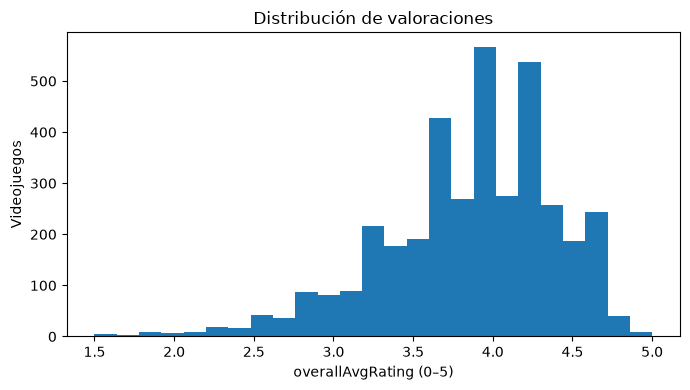

In [18]:
display(df_games['overallAvgRating'].describe().to_frame('valoración'))

plt.figure(figsize=(7, 4))
plt.hist(df_games['overallAvgRating'], bins=25)
plt.title('Distribución de valoraciones')
plt.xlabel('overallAvgRating (0–5)')
plt.ylabel('Videojuegos')
plt.tight_layout()
plt.show()


Como vemos, la mayoría de `overallAvgRating` están entre 3.5 y 4.3 estrellas.

### 5.2. Variables predictoras

Ahora vamos a hacer un describe sobre las variables que vamos a usar para predecir el `overallAvgRating`.

In [19]:
variables = [
    'developer', 'publisher', 'year',
    'baseAmount', 'ageLimit', 'isFree',
    'genres', 'supportedOperatingSystems'
]

display(df_games[variables].describe(include='all').T)
display(df_games[variables].isna().sum().to_frame('valores_faltantes'))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
developer,3800,2306,Lucasfilm,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
publisher,3800,1181,THQ Nordic GmbH,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3800.0,NaN,NaN,NaN,2013.865789,9.271284,1979.0,2009.0,2017.0,2021.0,2025.0
baseAmount,3800.0,NaN,NaN,NaN,14.809913,9.664363,0.0,7.99,13.69,19.99,73.99
ageLimit,3800.0,NaN,NaN,NaN,4.592895,6.740308,0.0,0.0,0.0,12.0,18.0
isFree,3800,2,False,3648,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genres,3800,746,"['Action', 'Adventure', 'Platformer']",112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
supportedOperatingSystems,3800,4,['windows'],2431,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,valores_faltantes
developer,0
publisher,0
year,0
baseAmount,0
ageLimit,0
isFree,0
genres,0
supportedOperatingSystems,0


### 5.3. Géneros y sistemas operativos

Ahora vamos a ver qué valores que hay en `supportedOperatingSystems` y `genres`

In [20]:
display(
    df_games[['title', 'genres', 'supportedOperatingSystems']].sample(10)
)

# Comprobamos si las listas están guardadas como texto.
print('Tipo de genres:', type(df_games['genres'].iloc[0]))
print('Tipo de supportedOperatingSystems:', type(df_games['supportedOperatingSystems'].iloc[0]))


,title,genres,supportedOperatingSystems
1285,Iron Storm,"['Shooter', 'Action', 'Sci-fi']",['windows']
4242,Armikrog,"['Adventure', 'Point-and-click', 'Puzzle']","['windows', 'mac', 'linux']"
3192,LEGRAND LEGACY: Tale of the Fatebounds,"['Action', 'Role-playing', 'Fantasy']",['windows']
8541,Omurice Next Time,"['Simulation', 'Point-and-click', 'Narrative']",['windows']
4700,Stardew Valley,"['Simulation', 'Role-playing', 'Managerial']","['windows', 'mac', 'linux']"
5429,Maize,"['Adventure', 'FPP', 'Sci-fi']",['windows']
2773,Black Legend,"['Role-playing', 'Strategy', '']",['windows']
8126,Aven Colony,"['Strategy', 'Simulation', 'Sci-fi']",['windows']
945,WARNO,"['Strategy', 'Real-time', 'Tactical']",['windows']
5374,Slay the Princess — The Pristine Cut,"['Adventure', 'Visual Novel', 'Horror']","['windows', 'mac', 'linux']"


Tipo de genres: <class 'str'>
Tipo de supportedOperatingSystems: <class 'str'>


In [21]:
display(
    df_games['supportedOperatingSystems'].value_counts()
)

supportedOperatingSystems
['windows']                    2431
['windows', 'mac', 'linux']     763
['windows', 'mac']              377
['windows', 'linux']            229
Name: count, dtype: int64

Como vemos tanto `genres` como `supportedOperatingSystems` son un string y nada mas. A su vez vemos que el dataset incluye 4 combinaciones de OS.
A nosotros nos va a convenir hacerlo una lista de Python y no dejarlo como strings, así pudiéndolo tratar de manera más efectiva.

Para esto vamos a usar el módulo ast que incorpora Python propiamente.

In [22]:
import ast

df_games['genres'] = df_games['genres'].apply(ast.literal_eval)
df_games['supportedOperatingSystems'] = df_games['supportedOperatingSystems'].apply(ast.literal_eval)

generos = df_games['genres']
sistemas = df_games['supportedOperatingSystems']

print('Géneros distintos:', generos.explode().nunique())
print('Frecuencia de los géneros:')
display(generos.explode().value_counts().to_frame('cantidad_videojuegos'))

print('Sistemas operativos:')
display(sistemas.explode().value_counts().to_frame('cantidad_videojuegos'))

Géneros distintos: 54
Frecuencia de los géneros:


,cantidad_videojuegos
genres,
Adventure,1625
Action,1406
Strategy,868
Role-playing,729
Fantasy,653
Sci-fi,591
Simulation,527
Puzzle,394
Point-and-click,356


Sistemas operativos:


,cantidad_videojuegos
supportedOperatingSystems,
windows,3800
mac,1140
linux,992


Podemos ver que hay 128 videojuegos que tienen de categoría una cadena vacía.

### 5.4. Géneros vacíos

Vimos que algunas listas de géneros incluyen una cadena vacía (`''`). Vamos a comprobarlo y quitar solamente esa etiqueta, sin eliminar los videojuegos.


In [23]:
display(
    df_games.loc[
        generos.apply(lambda lista: '' in lista),
        ['title', 'genres']
    ].head(15)
)

df_games['genres'] = generos.apply(
    lambda lista: [g for g in lista if g.strip()]
)

generos = df_games['genres']

print('Géneros distintos:', generos.explode().nunique())
print('Etiquetas vacías restantes:', generos.explode().eq('').sum())

,title,genres
35,Pizza Possum,"[Action, Strategy, ]"
94,FixFox,"[Adventure, Puzzle, ]"
99,Smushi Come Home,"[Adventure, TPP, ]"
192,Anodyne 2: Return to Dust,"[Adventure, Role-playing, ]"
199,The Textorcist: The Story of Ray Bibbia Demo,"[Action, Adventure, ]"
221,Tonight We Riot,"[Action, Arcade, ]"
288,"Warhammer 40,000: Shootas, Blood & Teef","[Action, Adventure, ]"
334,Carto,"[Adventure, Puzzle, ]"
409,Wild West Dynasty,"[Adventure, Simulation, ]"
422,Carto Demo,"[Adventure, Puzzle, ]"


Géneros distintos: 53
Etiquetas vacías restantes: 0


## 6. Predictores y separación de datos

Nosotros lo que vamos a querer predecir es el valor de `overallAvgRating`. Vamos a usar 2 algoritmos: regresión lineal y Random Forest Regressor (una forma de usar Random Forest para predecir valores numéricos).

Obviamente no vamos a usar `rating`, `filteredAvgRating`, `reviewCount` ni otros campos relacionados con el rating, ya que esto haría que se entrene sobre la respuesta.


Utilizamos `genres` como información principal de los géneros, en lugar de `category`, porque un videojuego puede tener varios. También incorporamos `supportedOperatingSystems` junto con `developer`, `publisher`, `year`, `baseAmount`, `ageLimit` e `isFree`.

Para `genres` creamos indicadores binarios de presencia por género. Las etiquetas vacías fueron eliminadas durante la limpieza del dataset y conservamos todos los géneros válidos, incluso aquellos que aparecen pocas veces.

También vamos a aplicar en las columnas categorícas de `developer` y `publisher` que haya un mínimo de 10 registros por el mismo motivo que `genres`: no sesgar el modelo.
<br>
<br>

---

<br>

`isFree` al ser una variable booleana la vamos a pasar a entero (1 = true y 0 = false), ya que los modelos se manejan mejor así.

Dividiremos el dataset en 80% para entrenamiento y 20% para prueba.

También vamos a crear una clase llamada `CodificadorMultietiqueta`. Esta clase va a ser utilizada para transformar listas de etiquetas en columnas numéricas binarias, donde 1 indica que una etiqueta está presente y 0 que no lo está. Esto nos va a permitir trabajar con los géneros y sistemas operativos de los videojuegos.

Esta clase va a heredar de `BaseEstimator` y `TransformerMixin`. `BaseEstimator` nos proporciona funcionalidades para gestionar los parámetros del estimador, mientras que `TransformerMixin` facilita la transformación de datos y permite utilizar el método `fit_transform()`.

El método `__init__(self, classes=None)` es básicamente el constructor. Cuando `classes` es `None`, significa que no especificamos previamente las etiquetas que queremos utilizar. Esto nos va a ser útil porque no tendremos que escribir manualmente los 53 géneros que identificamos en nuestro dataset.

El método `fit(self, X, y=None)` va a crear un objeto de la clase `MultiLabelBinarizer`, dado por scikit-learn, y ajustarlo con los datos recibidos. Este método va a recorrer las listas de Python e identificar las etiquetas únicas. Por ejemplo, si le pasamos `['Action', 'Adventure']` y `['Action', 'RPG']`, identificará `['Action', 'Adventure', 'RPG']`. Estas etiquetas quedarán almacenadas para utilizarlas luego durante la transformación.

El método `transform(self, X)` va a utilizar las etiquetas identificadas durante `fit()` para convertir las listas en columnas binarias. De esta manera, cada género tendrá su propia columna, donde 1 indicará que el videojuego pertenece a ese género y 0 que no pertenece.

Finalmente, esta clase nos permitirá utilizar `MultiLabelBinarizer` dentro del `ColumnTransformer` de nuestro Pipeline, para preparar las características antes de entrenar los modelos de regresión.

<br>
<br>

---

<br>

A su vez vamos a crear una función llamada `crear_preprocesador`. Esta función se va a encargar de preparar las variables antes de entrenar los modelos.

Como no todas las variables son iguales, le vamos a tener que dar distinto tratamiento a cada una. Esta función contiene 1 lista con cuatro transformaciones posibles. Cada transformación va a tener un nombre, un trasnformador (el objeto que va a realizar el procesamiento) y las columnas del dataframe a las que se le van a aplicar.
Las 5 transformaciones son:
- La de las variables categóricas: Van a ser en este caso `publisher` y `developer` y le vamos a aplicar la técnica de One Hot Encoding que consiste en básicamente hacer 1 columna por valor de la columna. Y, como dijimos antes, solo vamos a considerar aquellos casos donde hayan más de 10 casos presentes como distintos. A aquellos que tengan menos de 10 casos vamos a agruparlos todos así no perdemos ese dato.
- La de las variables numéricas: Van a ser cosas como `year`, `baseAmount`, `ageLimit`. Las vamos a escalar debido a que algunos modelos como el de regresión lineal trabaja mejor con datos escalados.
- Las binarias: `isFree` no le vamos a hacer ninguna transformación ya que está en modo binario (1 o 0)
- Los multivaluados que van a haber 2: Los `genre` que le vamos a aplicar la clase que comentamos antes y `supportedOperatingSystems` que también le vamos a aplicar la clase PERO, esto es importante, solo le vamos a dar importancia a MAC y a LINUX. Debido a que Windows está presente en todos los videojuegos no tendría mucho sentido dejarlo.

In [24]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MultiLabelBinarizer

class CodificadorMultietiqueta(BaseEstimator, TransformerMixin):
    def __init__(self, classes=None):
        self.classes = classes

    def fit(self, X, y=None):
        self.codificador_ = MultiLabelBinarizer(classes=self.classes)
        self.codificador_.fit(X)
        return self

    def transform(self, X):
        return self.codificador_.transform(X)


features = [
    'developer', 'publisher', 'year', 'baseAmount', 'ageLimit', 'isFree',
    'genres', 'supportedOperatingSystems'
]

X = df_games[features].copy()
X['isFree'] = X['isFree'].astype('int8')
y_reg = df_games['overallAvgRating'].astype(float)

X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

categoricas = ['developer', 'publisher']
numericas = ['year', 'baseAmount', 'ageLimit']
binarias = ['isFree']

def crear_preprocesador():
    transformaciones = [
        ('categoricas', OneHotEncoder(
            handle_unknown='infrequent_if_exist',
            min_frequency=10
        ), categoricas),

        ('numericas', StandardScaler(), numericas),

        ('binarias', 'passthrough', binarias),

        ('generos', CodificadorMultietiqueta(), 'genres'),

        ('sistemas',
         CodificadorMultietiqueta(classes=['linux', 'mac']),
         'supportedOperatingSystems')
    ]

    return ColumnTransformer(transformers=transformaciones)

print('Entrenamiento:', len(X_train), '| Prueba:', len(X_test))

Entrenamiento: 3040 | Prueba: 760


## 7. Experimento de regresión

Vamos a usar **Regresión Lineal** y **Random Forest Regressor** usando las diversas variables predictoras que tenemos.

Vamos a utilizar estos dos modelos debido a que nos permiten ambos predecir valores numéricos a partir de distintas features, cosa que nos será de gran utilidad para predecir el puntaje del videojuego.

La regresión lineal nos va a permitir encontrar una relación lineal entre las features y su valoración promedio, asignando distintos coeficientes a cada varaible.

También vamos a probar con random forest regressor debido a que es un algoritmo que nos permite encontrar relaciones no lineales e interacciones entre variables que quizá con regresión lineal no identificamos. Esto nos es útil debido a que quizá ciertas características como el precio y la valoración podrían variar según el género o el año de lanzamiento del juego.

Vamos a aplicar validaciones cruzadas de cinco particiones sobre el conjunto de entrenamiento y vamos a evaluar los resultados mediante MAE, RMSE y R^2.

<br>
<br>

En el caso de Random Forest Regressor le vamos a pasar ciertos parámetros:
- La cantidad de árboles de decisión que vamos a hacer (que después los vamos a promediar) que van a ser 100.
- La cantidad mínima de samples (videojuegos en este caso) que debe de contener cada cosa. Van a ser 5.
- La cantidad de características que debe de considerarse a la hora de que el árbol necesite dividir los datos, en este caso va a ser el 80%.

Básicamete el funcionamiento del random forest **regressor** es parecido a como funcionan los árboles de decisiones normales.
En los árboles de decisiones normales el algortimo encuentra una feature que permita dividir un conjunto de datos de la manera más representativa posible. Generalmente se usa para para clasificar, pero también existe la variante de árboles de regresión, que tienen el mismo concepto, estando al final de la hoja un valor (en este caso, una valoración).
Los random forest regressor hacen lo mismo, pero lo hacen mucha cantidad de veces (100 veces en nuestro caso) de manera random. Después cuando le pasamos un valor lo evaluará con estos 100 árboles y tomará el promedio de cada uno.
Cada árbol es distinto porque en random forest regressor cada uno de los árboles se forma con un conjunto de datos random del entrenamiento. Sumado a esto se le puede indicar cuantas features puede considerar EN CADA DIVISIÓN, en nuestro caso dijimos el 80%. Con esto obtenemos varios árboles distintos.

In [25]:
regresores = {
    'Regresión lineal': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, min_samples_leaf=5, max_features=0.8,
        n_jobs=-1, random_state=RANDOM_STATE)
}

cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring_reg = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
reg_cv = []
for nombre, estimador in regresores.items():
    modelo = Pipeline([('preprocesamiento', crear_preprocesador()), ('modelo', estimador)])
    scores = cross_validate(modelo, X_train, y_reg_train, cv=cv_reg,
                            scoring=scoring_reg, n_jobs=1)
    reg_cv.append({'Modelo': nombre, 'MAE_CV': -scores['test_MAE'].mean(),
                   'RMSE_CV': -scores['test_RMSE'].mean(), 'R2_CV': scores['test_R2'].mean()})

reg_cv_df = pd.DataFrame(reg_cv).sort_values('MAE_CV')
display(reg_cv_df)

c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWa

,Modelo,MAE_CV,RMSE_CV,R2_CV
1,Random Forest,0.400289,0.511086,0.125487
0,Regresión lineal,0.414054,0.526948,0.070220


Obtuvimos 3 métricas para ambos algoritmos:

MAE = Es el valor absoluto promedio entre la valoración real y la predicha. Por lo tanto cuanto más cercano a 0 sea, mejor. En este caso ganó Random Forest Regressor.

RMSE = Muy parecido a MAE, pero al ser al cuadrado penaliza aún más los errores grandes. Random Forest Regressor también fue mejor.

R2 = Nos dice  cuánto se reduce el error cuadrático total respecto de predecir siempre la media. RFR por ejemplo obtuvo un 12%, esto quiere decir que, en comparación con la media, logró reducir el error cuadrático total un 12%.

Como vemos los valores, en especial del R2, no son tan buenos, pero esto nos indica que los videojuegos tienen muchas más características que no son fácilemente predecibles, como una buena historia, un buen gameplay, etc....

### Evaluación final de regresión

Ahora vamos a testear nuestro modelo con el 20% que sacamos.

c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['Touring'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWa

,Modelo,MAE,RMSE,R2
1,Random Forest,0.396405,0.516474,0.091400
0,Regresión lineal,0.410944,0.529991,0.043219


c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['Touring'] will be ignored
  warnings.warn(
c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(


Seleccionado por MAE de CV: Random Forest


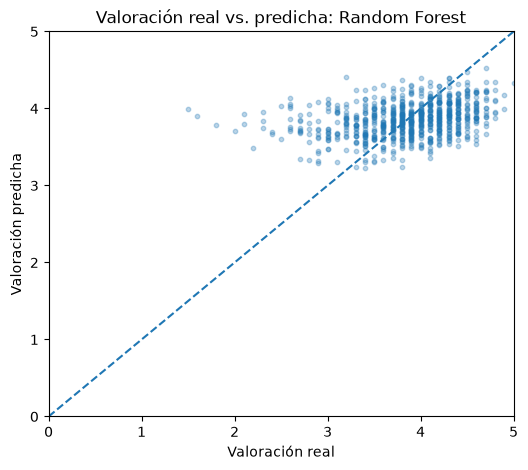

In [26]:
reg_test = []
reg_ajustados = {}
for nombre, estimador in regresores.items():
    modelo = Pipeline([('preprocesamiento', crear_preprocesador()), ('modelo', estimador)])
    modelo.fit(X_train, y_reg_train)
    pred = modelo.predict(X_test)
    reg_ajustados[nombre] = modelo
    reg_test.append({'Modelo': nombre,
                     'MAE': mean_absolute_error(y_reg_test, pred),
                     'RMSE': np.sqrt(mean_squared_error(y_reg_test, pred)),
                     'R2': r2_score(y_reg_test, pred)})
reg_test_df = pd.DataFrame(reg_test).sort_values('MAE')
display(reg_test_df)

ganador_reg = reg_cv_df.iloc[0]['Modelo']
print('Seleccionado por MAE de CV:', ganador_reg)
mejor_reg = reg_ajustados[ganador_reg]
pred_reg = mejor_reg.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_reg_test, pred_reg, s=10, alpha=0.3)
ax.plot([0, 5], [0, 5], linestyle='--')
ax.set(xlabel='Valoración real', ylabel='Valoración predicha', title=f'Valoración real vs. predicha: {ganador_reg}', xlim=(0, 5), ylim=(0, 5))
plt.show()

Como vemos se mantiene la tendencia de que Random Forest Regressor es mejor que regresión lineal y, tiene sentido. Porque ciertas variables pueden no tener una relación lineal, pueden llegar a quizá de depender de otras cosas. Por ejemplo un género en cierto año puede llegar a importar pero en otro año no.

In [27]:
import joblib

modelo_final = Pipeline([
    ('preprocesamiento', crear_preprocesador()), 
    ('modelo', RandomForestRegressor(
        n_estimators=100, 
        min_samples_leaf=5, 
        max_features=0.8,
        n_jobs=-1, 
        random_state=42
    ))
])

modelo_final.fit(X_train, y_reg_train)

joblib.dump(modelo_final, 'modelo_gog_rf.pkl')

c:\Users\lobas\OneDrive\Escritorio\Explotacion Proyecto FInal\Entrenamiento\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:1016: UserWarning: unknown class(es) ['windows'] will be ignored
  warnings.warn(


['modelo_gog_rf.pkl']